In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [3]:

data = pd.read_csv("/content/balance-scale.data")

print("First Five records")
print(data.head())
print("Last five records ")
print(data.tail())

X = data.iloc[:, 1:5]
y = data.iloc[:, 0]

print("\n Input feature:")
print(X.head())
print("\n Target variable:")
print(y.head())

First Five records
   B  1  1.1  1.2  1.3
0  R  1    1    1    2
1  R  1    1    1    3
2  R  1    1    1    4
3  R  1    1    1    5
4  R  1    1    2    1
Last five records 
     B  1  1.1  1.2  1.3
619  L  5    5    5    1
620  L  5    5    5    2
621  L  5    5    5    3
622  L  5    5    5    4
623  B  5    5    5    5

 Input feature:
   1  1.1  1.2  1.3
0  1    1    1    2
1  1    1    1    3
2  1    1    1    4
3  1    1    1    5
4  1    1    2    1

 Target variable:
0    R
1    R
2    R
3    R
4    R
Name: B, dtype: object


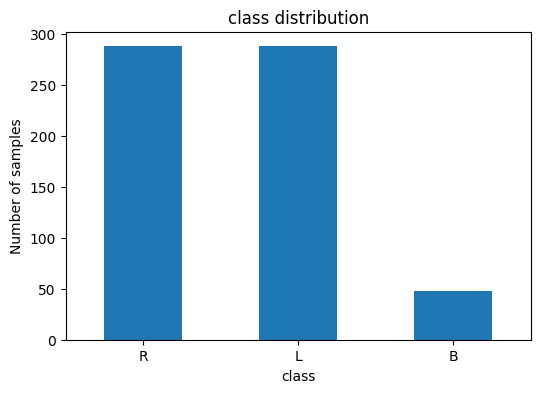


 class prior P(ci):
[0.08256881 0.46100917 0.45642202]
[[3.05555556 2.88888889 2.97222222 2.97222222]
 [3.68159204 3.58706468 2.3681592  2.47761194]
 [2.40201005 2.3718593  3.65326633 3.63316583]]
[[2.10802469 2.04320988 2.13811729 2.02700617]
 [1.30160145 1.55585258 1.77490656 1.78183709]
 [1.81828742 1.81146941 1.58329335 1.56895028]]
[[ 0  7  5]
 [ 0 87  0]
 [ 0  2 87]]


In [4]:
class_count = y.value_counts()
plt.figure(figsize=(6, 4))
class_count.plot(kind="bar")
plt.title("class distribution")
plt.xlabel("class")
plt.ylabel("Number of samples")
plt.xticks(rotation=0)
plt.show()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42
)

model = GaussianNB()
model.fit(X_train, y_train)

print("\n class prior P(ci):")
print(model.class_prior_)
print(model.theta_)
print(model.var_)

y_pred = model.predict(X_test)
cm = confusion_matrix(y_test, y_pred)
print(cm)


92.5531914893617

 classification Report
              precision    recall  f1-score   support

           B       0.00      0.00      0.00        12
           L       0.91      1.00      0.95        87
           R       0.95      0.98      0.96        89

    accuracy                           0.93       188
   macro avg       0.62      0.66      0.64       188
weighted avg       0.87      0.93      0.90       188



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


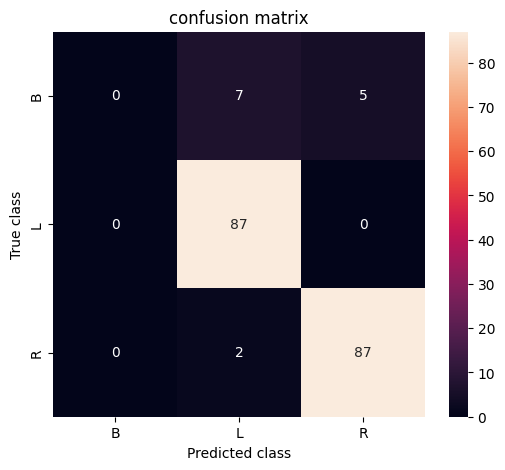

In [5]:
accuracy = accuracy_score(y_test, y_pred)
print(accuracy * 100)

print("\n classification Report")
print(classification_report(y_test, y_pred))

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)
plt.title("confusion matrix")
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.show()